# Models: LogReg, Tree, KNN, RF, SVM

## Load // Analyze dataset

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Telco-Customer-Churn.csv')

print(df.shape)
print(df.head())
print(df.describe())
print(df.info())

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

## Data cleaning / Feature engineering

In [63]:
# # 1 drop ID
# df = df.drop(columns=['customerID'])
#
# # check missing and duplicates
# # print(df.isnull().sum())
# # print(df.duplicated().sum())
# # no missing no duplicates
#
# # 2 fix TotalCharges str -> numeric and handle nan
# df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r"^\s*$", pd.NA, regex=True), errors='coerce')
# df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
#
# # 3 Encoding column for 1 and 0:
# bin_cols = [
#     "gender",
#     "Partner",
#     "Dependents",
#     "PhoneService",
#     "PaperlessBilling",
#     "Churn"
# ]
#
# for col in bin_cols:
#     if col == 'gender':
#         df[col] = df[col].map({'Female': 0, 'Male': 1})
#     else:
#         df[col] = df[col].map({'No': 0, 'Yes': 1})
#
#
# # 4 one hot encoding (multicategory columns)
# multi_cols = [
#     "MultipleLines",
#     "InternetService",
#     "OnlineSecurity",
#     "OnlineBackup",
#     "DeviceProtection",
#     "TechSupport",
#     "StreamingTV",
#     "StreamingMovies",
#     "Contract",
#     "PaymentMethod"
# ]
#
# df = pd.get_dummies(
#     df,
#     columns=multi_cols,
#     drop_first=True,
#     dtype=int,
# )
#
# print(df.head())
# print(df.shape)
#
# df_smth = df.copy()

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   PaperlessBilling  MonthlyCharges  TotalCharges  Churn  ...  \
0                 1           29.85         29.85      0  ...   
1                 0           56.95       1889.50      0  ...   
2                 1           53.85        108.15      1  ...   
3                 0           42.30       1840.75      0  ...   
4                 1           70.70        151.65      1  ...   

   TechSupport_Yes  StreamingTV_No internet service  StreamingTV_Yes  \
0                0                                0                0   
1                0                    

## Tenure grouped // each age group leaving percentage

In [64]:
# use cut method
df['tenure_grouped'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, float('inf')],
    labels=['0-12', '13-24', '25-48', '49+']
)

pd.crosstab(df['tenure_grouped'], df['Churn'], normalize='index')

# tenure_grouped	No                      Yes
# 0-12	            0.525618	            0.474382
# 13-24	            0.712891	            0.287109
# 25-48	            0.796110	            0.203890
# 49+	            0.904868	            0.09513

# conclusion from here, if person stayed little , theres high possibility that he leaves

Churn,0,1
tenure_grouped,,
0-12,0.525618,0.474382
13-24,0.712891,0.287109
25-48,0.796110,0.203890
49+,0.904868,0.095132


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   gender                                 7043 non-null   int64   
 1   SeniorCitizen                          7043 non-null   int64   
 2   Partner                                7043 non-null   int64   
 3   Dependents                             7043 non-null   int64   
 4   tenure                                 7043 non-null   int64   
 5   PhoneService                           7043 non-null   int64   
 6   PaperlessBilling                       7043 non-null   int64   
 7   MonthlyCharges                         7043 non-null   float64 
 8   TotalCharges                           7043 non-null   float64 
 9   Churn                                  7043 non-null   int64   
 10  MultipleLines_No phone service         7043 non-null   int64   
 11  Mu

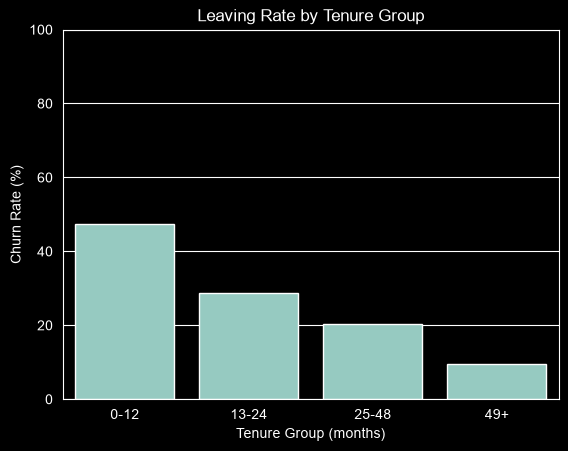

In [66]:
churn_rate = pd.crosstab(
    df['tenure_grouped'],
    df['Churn'],
    normalize='index'
)[1] * 100

sns.barplot(x=churn_rate.index, y=churn_rate.values)

plt.xlabel('Tenure Group (months)')
plt.ylabel('Churn Rate (%)')
plt.title('Leaving Rate by Tenure Group')
plt.ylim(0, 100)

# kam ishlatgan userla tez ketib qoladi

print(df.info())

## 1 Logistic Regression

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Churn', 'tenure_grouped'])
y = df['Churn']

num_cols = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

print(lr.score(X_test, y_test)) # 0.8055358410220014

0.8055358410220014


In [69]:
from sklearn.metrics import confusion_matrix, classification_report


print(confusion_matrix(y_test, lr.predict(X_test)))
print(classification_report(y_test, lr.predict(X_test)))

[[926 109]
 [165 209]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## 2 Decision Tree

In [73]:
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)
print(clf.score(X_test, y_test))
print(clf.score(X_train, y_train))
# max depth 4 da eng kam farq chiqdi
# 0.7955997161107168
# 0.7925097621583245

0.7955997161107168
0.7925097621583245


0.7925097621583245

In [74]:
print(confusion_matrix(y_test, clf.predict(X_test)))
print(classification_report(y_test, clf.predict(X_test)))

[[929 106]
 [182 192]]
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



## 3 KNN

In [87]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


k_values = range(1, 51)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))

best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("Best k:", best_k)
print("Best test accuracy:", best_accuracy)
# Best k: 36
# Best test accuracy: 0.794889992902768

Best k: 36
Best test accuracy: 0.794889992902768


## 4 Random Forest

In [93]:
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


rf = RandomForestClassifier(n_estimators=200, max_depth=4 ,random_state=42)
rf.fit(X_train, y_train)

print(rf.score(X_test, y_test))
print(rf.score(X_train, y_train))

print(classification_report(y_test, rf.predict(X_test)))

0.7842441447835344
0.7942847000354988
              precision    recall  f1-score   support

           0       0.80      0.94      0.86      1035
           1       0.68      0.35      0.46       374

    accuracy                           0.78      1409
   macro avg       0.74      0.65      0.66      1409
weighted avg       0.77      0.78      0.76      1409



## 5 SVM

In [94]:
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.fit_transform(X_test[num_cols])

svm = SVC(random_state=42)
svm.fit(X_train, y_train)
print(len(svm.support_))

print(svm.score(X_test, y_test))
print(svm.score(X_train, y_train))

print(classification_report(y_test, svm.predict(X_test)))



2620
0.7927608232789212
0.8173588924387647
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.65      0.47      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409

